# Gráficas para el problema 2

Cargando datos reales del edificio 838...

Total de muestras válidas 2.4 GHz: 406773
Total de muestras válidas 5 GHz: 49208

Gráfica guardada exitosamente en: figures/histograma_rssi_cisco.pdf


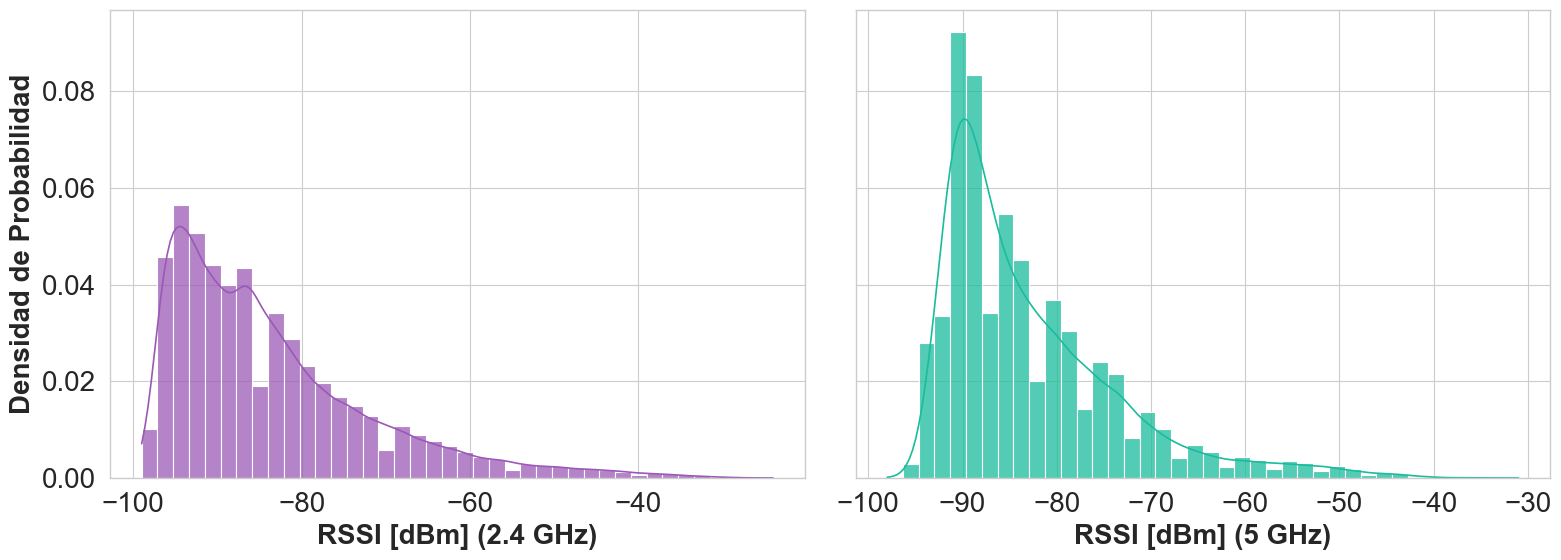

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from data.data_loader import load_distributions

# 1. Asegurar que existe la carpeta para guardar las figuras
os.makedirs('figures', exist_ok=True)

# 2. Configurar el estilo gráfico para el paper (tesis)
plt.style.use('seaborn-v0_8-paper')
sns.set_theme(style="whitegrid", context="paper")

# Configuración global de fuentes a tamaño 20
plt.rcParams.update({
    'font.size': 20,
    'axes.labelsize': 20,
    'axes.titlesize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20,
    'legend.title_fontsize': 20
})

# 3. Cargar las distribuciones de datos reales
building_id = "838" 
print(f"Cargando datos reales del edificio {building_id}...")
distributions = load_distributions(building_id=building_id, verbose=False)

# 4. Extraer todas las mediciones reales de la estructura de bloques
g24_list = []
g5_list = []

for dist in distributions:
    for block in dist.blocks:
        g24 = block.datos['G_2_4'].dropna().values
        g5 = block.datos['G_5'].dropna().values
        
        g24_list.extend(g24)
        g5_list.extend(g5)

# 5. Convertir a numpy arrays y calcular el RSSI real (RSSI = Gain + P_TX)
P_tx = 14.0
rssi_24g = np.array(g24_list) + P_tx
rssi_5g = np.array(g5_list) + P_tx

print(f"\nTotal de muestras válidas 2.4 GHz: {len(rssi_24g)}")
print(f"Total de muestras válidas 5 GHz: {len(rssi_5g)}")

# 6. Generar el Histograma Empírico en Subplots (1 fila, 2 columnas)
custom_colors = ["#9B59B6", "#1ABC9C"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Subplot 1: 2.4 GHz
sns.histplot(rssi_24g, bins=40, color=custom_colors[0], alpha=0.75, stat='density', kde=True, ax=axes[0])
axes[0].set_xlabel("RSSI [dBm] (2.4 GHz)", fontweight='bold')
axes[0].set_ylabel("Densidad de Probabilidad", fontweight='bold')

# Subplot 2: 5 GHz
sns.histplot(rssi_5g, bins=40, color=custom_colors[1], alpha=0.75, stat='density', kde=True, ax=axes[1])
axes[1].set_xlabel("RSSI [dBm] (5 GHz)", fontweight='bold')
axes[1].set_ylabel("") # Ocultamos el label del eje Y porque comparten la misma escala (sharey=True)

# Ajuste automático de márgenes para que nada quede recortado
plt.tight_layout()

# 7. Guardar en PDF de alta calidad
output_path = "figures/histograma_rssi_cisco.pdf"
plt.savefig(output_path, format='pdf', bbox_inches='tight', dpi=300)
print(f"\nGráfica guardada exitosamente en: {output_path}")

plt.show()


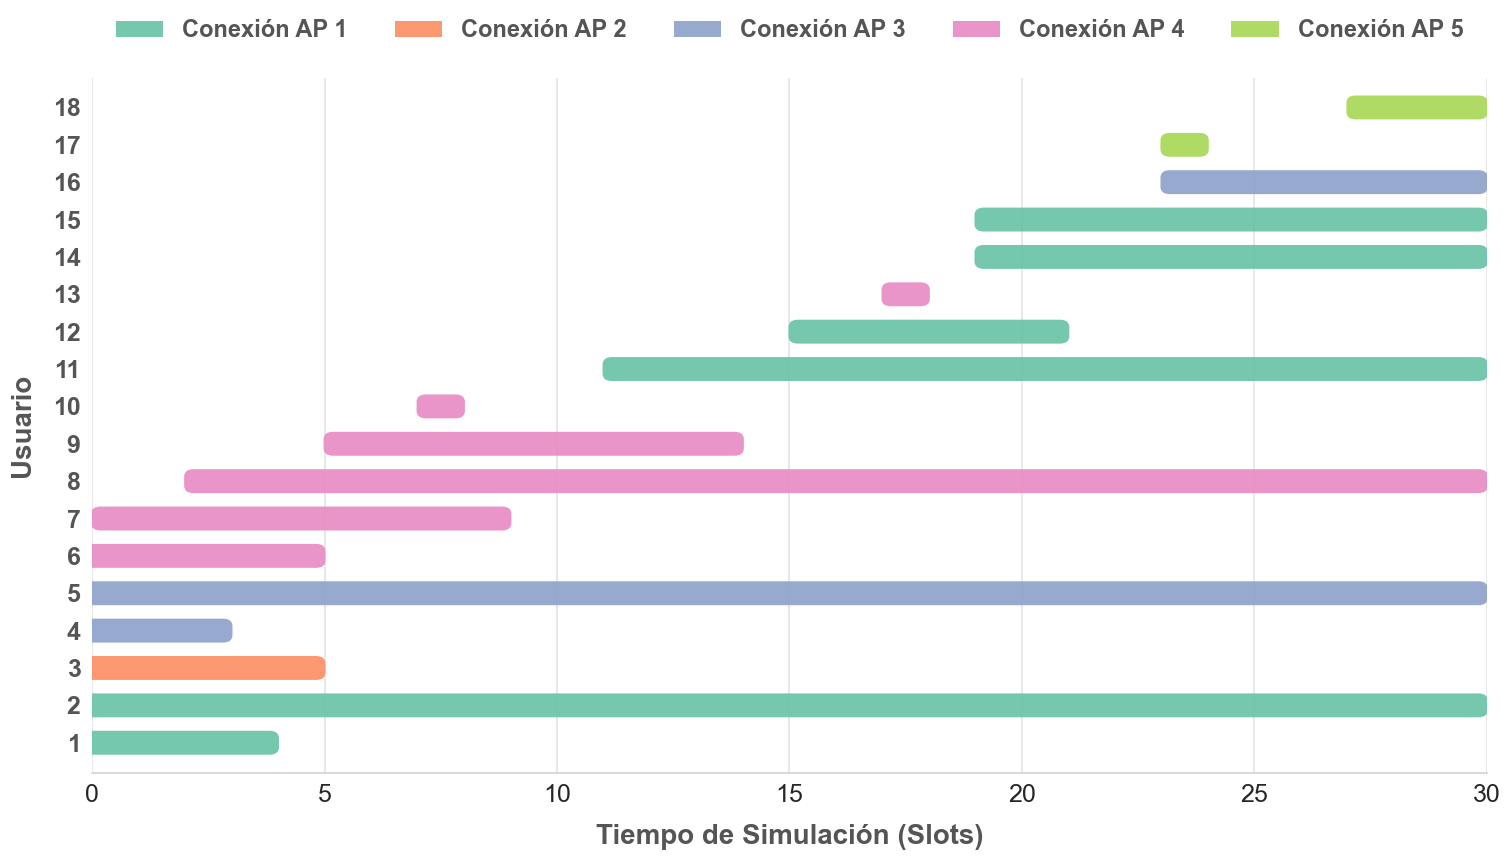

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
import os

from simulation.arrival_departure_model import ArrivalDepartureModel
from data.data_loader import load_distributions

os.makedirs('figures', exist_ok=True)
plt.style.use('default')
sns.set_theme(style="white", context="paper")

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    'legend.fontsize': 20,
    'axes.edgecolor': '#D3D3D3',
    'axes.linewidth': 1.2
})

def plot_dinamica_aesthetic_warmup():
    T = 30            # Ventana de tiempo que queremos ver (Eje X)
    warmup_slots = 20 # Cuánto tiempo "calentamos" la red antes del t=0
    
    # Cargar datos reales
    distributions = load_distributions(building_id="990", verbose=False)
    
    # Simulamos el tiempo total (Warmup + Visualización)
    model = ArrivalDepartureModel(
        distribuciones=distributions,
        mean_arrival=1.5,
        mean_duration=15.0,
        total_timesteps=T + warmup_slots,
        delta_mean=3,
        random_seed=43 # Ajustado para que caigan lindos clientes en el corte t=0
    )
    
    events, _ = model.simulate_all_events()
    
    mac_to_id = {}
    clientes = []
    
    for ev in events:
        # Desplazamos el tiempo de llegada y salida para restar el warmup
        arr_shifted = ev.arrival_time - warmup_slots
        dep_shifted = ev.departure_time - warmup_slots
        
        # Filtramos: Solo clientes que "sobreviven" pasando t=0 y llegan antes de T
        if dep_shifted > 0 and arr_shifted < T:
            dist = distributions[ev.distribution_idx]
            ap_id = 1 
            if len(dist.blocks) > 0:
                datos_bloque = dist.blocks[0].datos
                try:
                    best_idx = datos_bloque['G_2_4'].idxmax()
                    mac_ganadora = datos_bloque.loc[best_idx, 'mac_ap'] if 'mac_ap' in datos_bloque.columns else best_idx 
                    if mac_ganadora not in mac_to_id:
                        mac_to_id[mac_ganadora] = len(mac_to_id) + 1
                    ap_id = mac_to_id[mac_ganadora]
                except Exception:
                    pass
                
            clientes.append({
                'id': len(clientes) + 1,
                'arr': arr_shifted, # Notar que esto puede ser negativo!
                'dur': ev.duration,
                'ap': ap_id
            })
            
            # Frenamos en 18 usuarios
            if len(clientes) >= 18:
                break

    # --- Configuración de Figura ---
    fig, ax = plt.subplots(figsize=(16, 9))
    
    aps_unicos = sorted(list(set(c['ap'] for c in clientes)))
    base_colors = sns.color_palette("Set2", len(aps_unicos))
    color_map = {ap: base_colors[i] for i, ap in enumerate(aps_unicos)}
    
    labels_added = set()
    
    for i, cli in enumerate(clientes):
        arr, dur, ap = cli['arr'], cli['dur'], cli['ap']
        color = color_map[ap]
        
        label = f"Conexión AP {ap}" if ap not in labels_added else ""
        labels_added.add(ap)
        
        bbox = FancyBboxPatch((arr, i - 0.3), dur, 0.6,
                              boxstyle="round,pad=0.02,rounding_size=0.2", 
                              facecolor=color, alpha=0.9, 
                              edgecolor='none', label=label)
        ax.add_patch(bbox)

    # --- Limpieza Visual ---
    ax.set_ylim(-0.8, len(clientes) - 0.2)
    ax.set_yticks(range(len(clientes)))
    
    # -------------------------------------------------------------
    # CAMBIO: Solo el número en cada fila
    ax.set_yticklabels([f"{c['id']}" for c in clientes], color='#555555', fontweight='600')
    # CAMBIO: La palabra "Usuario" como etiqueta del eje Y global
    ax.set_ylabel("Usuario", color='#555555', fontweight='bold', labelpad=12)
    # -------------------------------------------------------------
    
    ax.set_xlabel("Tiempo de Simulación (Slots)", color='#555555', fontweight='bold', labelpad=12)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    ax.grid(axis='x', color='#E8E8E8', linestyle='-', linewidth=1.5)
    ax.grid(axis='y', visible=False) 
    ax.set_axisbelow(True) 
    
    # CLAVE: Forzamos el corte en 0
    ax.set_xlim(0, T)
    
    # Leyenda
    handles, labels = ax.get_legend_handles_labels()
    valid_idx = [i for i, l in enumerate(labels) if l]
    
    leg = ax.legend([handles[i] for i in valid_idx], [labels[i] for i in valid_idx], 
                    loc='lower center', bbox_to_anchor=(0.5, 1.02),
                    ncol=len(valid_idx), frameon=False, fontsize=17)
    
    for text in leg.get_texts():
        text.set_color('#555555')
        text.set_fontweight('600')
    
    plt.tight_layout()
    
    # Guardado en formato SVG Vectorial
    # Guardado en formato PDF de alta resolución
    output_path = "figures/dinamica_aesthetic.pdf"
    plt.savefig(output_path, format='pdf', dpi=300, bbox_inches='tight')

    plt.show()

plot_dinamica_aesthetic_warmup()



Grafo topológico minimalista guardado en: figures/grafo_heterogeneo_limpio.svg


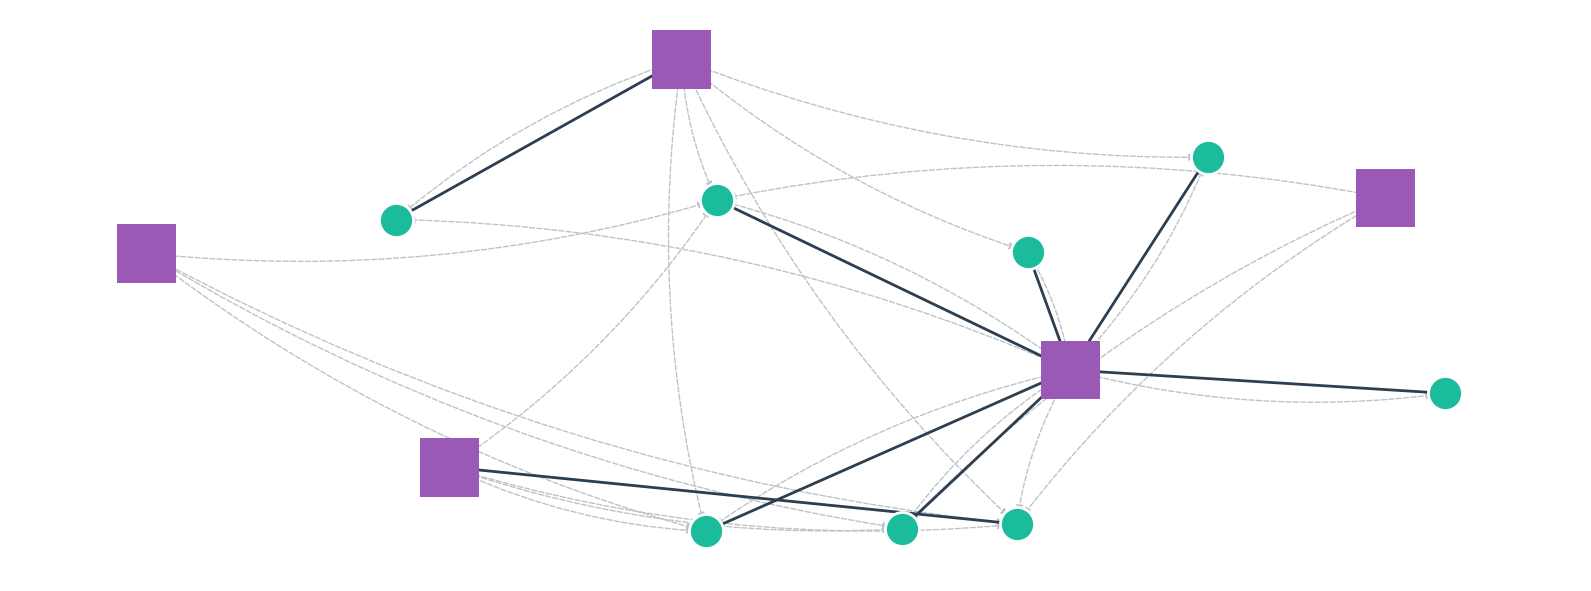

In [28]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import networkx as nx
import seaborn as sns
import os

from model.network_graph_env import NetworkGraphEnv
from data.data_loader import load_distributions

os.makedirs('figures', exist_ok=True)
plt.style.use('default')
sns.set_theme(style="white", context="paper")

def plot_grafo_heterogeneo_limpio():
    distributions = load_distributions(building_id="990", verbose=False)
    n_aps = len(distributions[0].blocks[0].datos)
    
    env = NetworkGraphEnv(
        distributions=distributions,
        n_aps=n_aps,
        building_id="990",
        mean_arrival=4.0,
        mean_duration=15.0,
        total_timesteps=100,
        warmup_steps=20, 
        random_seed=42,
        ap_feature_mode='static_id'
    )
    
    obs, _ = env.reset()
    
    if obs['client'].num_nodes == 0:
        env.random_seed = 99
        obs, _ = env.reset()
    
    G = nx.DiGraph()
    
    for i in range(obs['ap'].num_nodes):
        G.add_node(f"AP_{i}", type='AP')
        
    for i in range(obs['client'].num_nodes):
        G.add_node(f"CLI_{i}", type='Client')
        
    # Agregamos las aristas de visibilidad (AP -> Cliente)
    edge_index_down = obs['ap', 'connects', 'client'].edge_index
    edge_attr_down = obs['ap', 'connects', 'client'].edge_attr
    for k in range(edge_index_down.shape[1]):
        u = edge_index_down[0, k].item()
        v = edge_index_down[1, k].item()
        w = edge_attr_down[k, 0].item()
        G.add_edge(f"AP_{u}", f"CLI_{v}", type='connects', weight=w)
        
    # Agregamos las aristas de asociación activa (Cliente -> AP)
    edge_index_up = obs['client', 'connected_to', 'ap'].edge_index
    for k in range(edge_index_up.shape[1]):
        u = edge_index_up[0, k].item()
        v = edge_index_up[1, k].item()
        G.add_edge(f"CLI_{u}", f"AP_{v}", type='connected_to')

    # Limpiamos nodos huerfanos para centrar la visual en el cluster activo
    aislados = list(nx.isolates(G))
    if len(aislados) < len(G.nodes):
        G.remove_nodes_from(aislados)

    fig, ax = plt.subplots(figsize=(16, 6))
    
    ap_nodes = [n for n, d in G.nodes(data=True) if d['type'] == 'AP']
    cli_nodes = [n for n, d in G.nodes(data=True) if d['type'] == 'Client']
    
    pos = nx.spring_layout(G, k=2.0, iterations=100, seed=42)
    
    edges_connects = [(u, v) for u, v, d in G.edges(data=True) if d['type'] == 'connects']
    edges_connected_to = [(u, v) for u, v, d in G.edges(data=True) if d['type'] == 'connected_to']
    
    # --- DIBUJAR NODOS --- custom_colors = ["#9B59B6", "#1ABC9C"]

    # APs como cuadrados grandes celestes
    nx.draw_networkx_nodes(G, pos, nodelist=ap_nodes, node_color="#9B59B6", node_shape="s", 
                           node_size=1800, edgecolors="none", ax=ax)
    
    # Clientes como círculos verdes más pequeños
    nx.draw_networkx_nodes(G, pos, nodelist=cli_nodes, node_color="#1ABC9C", node_shape="o", 
                           node_size=600, edgecolors="white", linewidths=2.0, ax=ax)
    
    # --- DIBUJAR ARISTAS ---
    # 1. Bajada (Visibilidad RSSI): Gris y punteado
    nx.draw_networkx_edges(G, pos, edgelist=edges_connects, edge_color="#BDC3C7", 
                           style="dashed", arrows=True, arrowsize=10, connectionstyle="arc3,rad=0.1", ax=ax)
    
    # 2. Subida (Asociación Real): Azul oscuro firme
    nx.draw_networkx_edges(G, pos, edgelist=edges_connected_to, edge_color="#2C3E50", 
                           style="solid", arrows=True, arrowsize=15, width=2.0, ax=ax)
    
    ax.axis("off") 
    
    plt.tight_layout()
    output_path = "figures/grafo_heterogeneo_limpio.svg"
    plt.savefig(output_path, format='svg', bbox_inches='tight', transparent=True)
    print(f"\nGrafo topológico minimalista guardado en: {output_path}")

    plt.show()

plot_grafo_heterogeneo_limpio()


Cargando y calculando la matriz histórica real del edificio 990...
Cargando matriz histórica desde data/matrices_atenuacion/matriz_b990.pkl...

Heatmap de Interferencia guardado en: figures/matriz_interferencia_heatmap.pdf


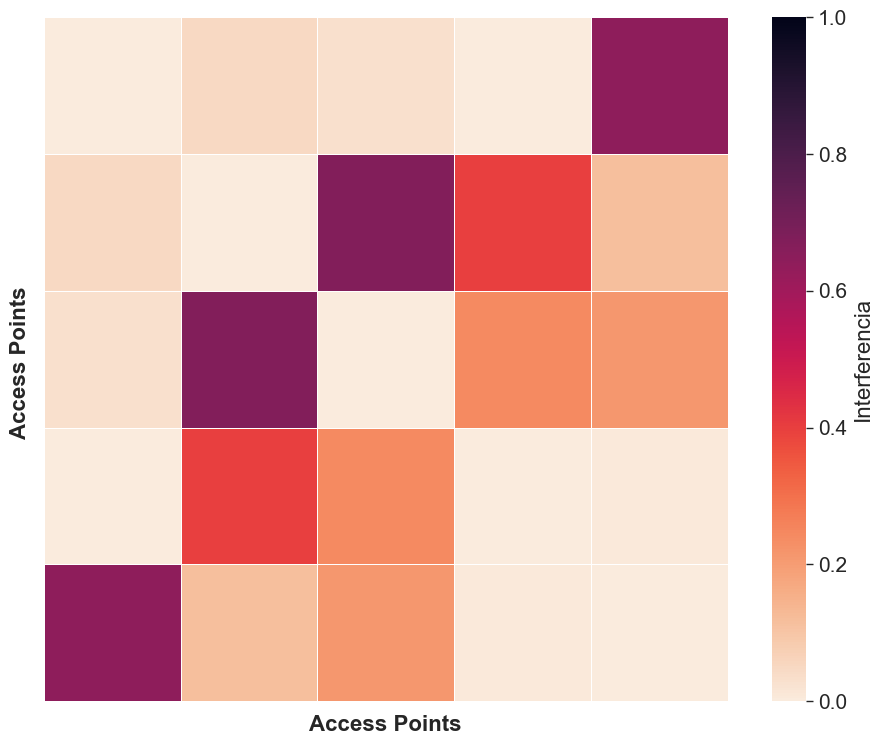

In [11]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os

from utils.positional_encoding import obtener_matriz_atenuacion_historica

# 1. Asegurar la carpeta y estilo
os.makedirs('figures', exist_ok=True)
plt.style.use('default')
sns.set_theme(style="white", context="paper")

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 25,
    'axes.labelsize': 16,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
})

def plot_matriz_interferencia():
    print("Cargando y calculando la matriz histórica real del edificio 990...")
    # 2. Cargar matriz de atenuaciones (en dBm) del dataset real
    matriz_atenuacion, aps = obtener_matriz_atenuacion_historica(building_id="990", load_if_exists=True)
    
    # 3. Mapear a rango Normalizado [0, 1] usando TU lógica de Positional Encoding
    mat_segura = np.nan_to_num(matriz_atenuacion, neginf=-100.0)
    A = np.clip((mat_segura + 100.0) / 70.0, 0.0, 1.0)
    
    # Simetrizar y anular la diagonal (auto-interferencia no aplica al modelo mutuo)
    A = (A + A.T) / 2.0
    np.fill_diagonal(A, 0.0)
    
    # 4. Filtrar APs desconectados para que el heatmap sea denso e interesante
    activos = np.sum(A, axis=1) > 0.05
    A_activa = A[activos][:, activos]
    
    # 5. Dibujar el Heatmap
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # 'rocket_r' es una paleta de Seaborn que va de blanco a colores cálidos oscuros. Queda muy tesis.
    sns.heatmap(
        A_activa,
        cmap="rocket_r",
        vmin=0.0, vmax=1.0,
        square=True,
        cbar_kws={'label': 'Interferencia'},
        xticklabels=False, # Ocultamos los nombres largos de los APs para más limpieza
        yticklabels=False,
        linewidths=0.5,
        linecolor='white',
        ax=ax
    )
    
    # Ejes limpios
    ax.set_xlabel("Access Points", fontweight='bold', labelpad=10)
    ax.set_ylabel("Access Points ", fontweight='bold', labelpad=10)
    
    plt.tight_layout()
    output_path = "figures/matriz_interferencia_heatmap.pdf"
    plt.savefig(output_path, format='pdf', bbox_inches='tight', dpi=300)
    print(f"\nHeatmap de Interferencia guardado en: {output_path}")

    plt.show()

plot_matriz_interferencia()
